
## Tugas Praktikum 3: Classification dengan Ensemble Method & Class Imbalance

| NRP | Nama |
|---|---|
| 5054251013 | Evina Fitriyani |

### 1. Import Dataset

Dataset yang digunakan adalah Credit Card Fraud Detection dari Kaggle. Dataset ini berisi transaksi kartu kredit dengan atribut numerik dan kolom `Class` sebagai label, yaitu 0 untuk transaksi normal dan 1 untuk transaksi fraud.

Dataset: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

File yang digunakan adalah `creditcard.csv`.


In [27]:

# import library yang dibutuhkan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from imblearn.over_sampling import SMOTE

pd.set_option('display.max_columns', None)
RANDOM_STATE = 42


In [28]:

# import dataset creditcard.csv

df = pd.read_csv('creditcard.csv')
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [29]:

# cek ukuran dataset
print('Ukuran dataset:', df.shape)


Ukuran dataset: (284807, 31)


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [31]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000



## 2. Analisis Distribusi Kelas

Sebelum membangun model, distribusi kelas pada atribut `Class` diperiksa terlebih dahulu untuk mengetahui perbandingan transaksi normal dan transaksi fraud. Pemeriksaan ini penting karena jumlah transaksi fraud biasanya jauh lebih sedikit dibandingkan transaksi normal, sehingga dapat menyebabkan class imbalance.


In [32]:

# hitung jumlah dan persentase setiap kelas

jumlah_kelas = df['Class'].value_counts().sort_index()
persen_kelas = df['Class'].value_counts(normalize=True).sort_index() * 100

distribusi_kelas = pd.DataFrame({
    'Jumlah Transaksi': jumlah_kelas,
    'Persentase (%)': persen_kelas
})

distribusi_kelas.index = ['Normal (0)', 'Fraud (1)']

display(distribusi_kelas)


,Jumlah Transaksi,Persentase (%)
Normal (0),284315,99.827251
Fraud (1),492,0.172749


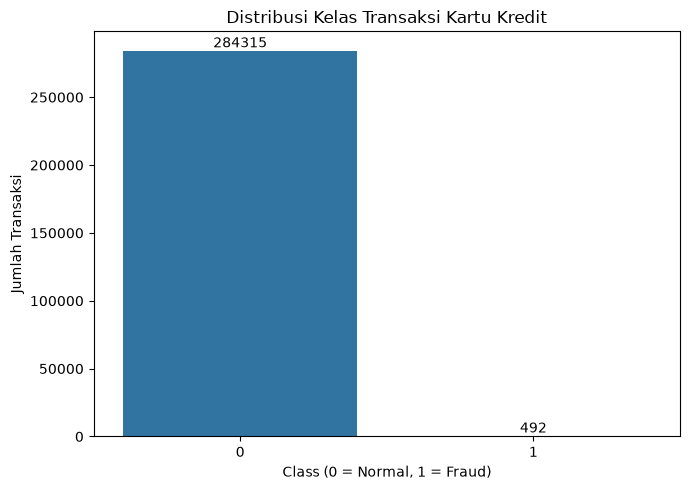

In [18]:

# visualisasi distribusi kelas

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x='Class')

ax.set_title('Distribusi Kelas Transaksi Kartu Kredit')
ax.set_xlabel('Class (0 = Normal, 1 = Fraud)')
ax.set_ylabel('Jumlah Transaksi')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()



Berdasarkan tabel dan grafik di atas, distribusi kelas dapat diamati melalui jumlah dan persentase transaksi normal serta fraud. Jika jumlah transaksi fraud jauh lebih sedikit, dataset termasuk tidak seimbang (*imbalanced dataset*).

Kondisi tersebut perlu diperhatikan karena model dapat cenderung memprediksi kelas mayoritas dan kurang mengenali transaksi fraud.



## 3. Pembagian Data dan Penanganan Class Imbalance

Dataset dibagi menjadi data latih sebesar 80% dan data uji sebesar 20% menggunakan `train_test_split` dengan `stratify=y`. Stratifikasi digunakan agar proporsi kelas pada data latih dan data uji tetap mendekati distribusi kelas awal.

Penanganan class imbalance dilakukan menggunakan metode SMOTE (*Synthetic Minority Over-sampling Technique*). SMOTE membentuk sampel sintetis pada kelas minoritas. Resampling hanya dilakukan pada data latih agar data uji tetap mempertahankan distribusi aslinya dan tidak terjadi kebocoran data (*data leakage*).


In [33]:

# pisahkan fitur dan target
X = df.drop(columns=['Class'])
y = df['Class']

# bagi data dengan perbandingan 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Ukuran X_train:', X_train.shape)
print('Ukuran X_test :', X_test.shape)
print('Ukuran y_train:', y_train.shape)
print('Ukuran y_test :', y_test.shape)


Ukuran X_train: (227845, 30)
Ukuran X_test : (56962, 30)
Ukuran y_train: (227845,)
Ukuran y_test : (56962,)


In [34]:

# periksa distribusi kelas setelah train-test split
print('Distribusi kelas data latih:')
display(y_train.value_counts().sort_index().rename('Jumlah'))

print('Distribusi kelas data uji:')
display(y_test.value_counts().sort_index().rename('Jumlah'))


Distribusi kelas data latih:


Class
0    227451
1       394
Name: Jumlah, dtype: int64

Distribusi kelas data uji:


Class
0    56864
1       98
Name: Jumlah, dtype: int64

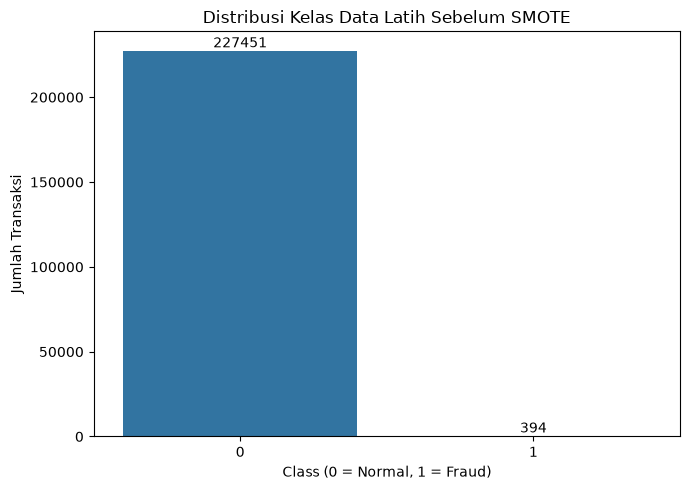

In [35]:

# visualisasi distribusi kelas data latih sebelum SMOTE

plt.figure(figsize=(7, 5))

ax = sns.countplot(x=y_train)

ax.set_title('Distribusi Kelas Data Latih Sebelum SMOTE')
ax.set_xlabel('Class (0 = Normal, 1 = Fraud)')
ax.set_ylabel('Jumlah Transaksi')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()


In [36]:

# terapkan SMOTE hanya pada data latih
smote = SMOTE(
    sampling_strategy=0.1,
    random_state=RANDOM_STATE
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print('Distribusi kelas sebelum SMOTE:')
display(y_train.value_counts().sort_index().rename('Jumlah'))

print('Distribusi kelas setelah SMOTE:')
display(y_train_smote.value_counts().sort_index().rename('Jumlah'))

print('Ukuran data latih sebelum SMOTE:', X_train.shape)
print('Ukuran data latih setelah SMOTE :', X_train_smote.shape)


Distribusi kelas sebelum SMOTE:


Class
0    227451
1       394
Name: Jumlah, dtype: int64

Distribusi kelas setelah SMOTE:


Class
0    227451
1     22745
Name: Jumlah, dtype: int64

Ukuran data latih sebelum SMOTE: (227845, 30)
Ukuran data latih setelah SMOTE : (250196, 30)


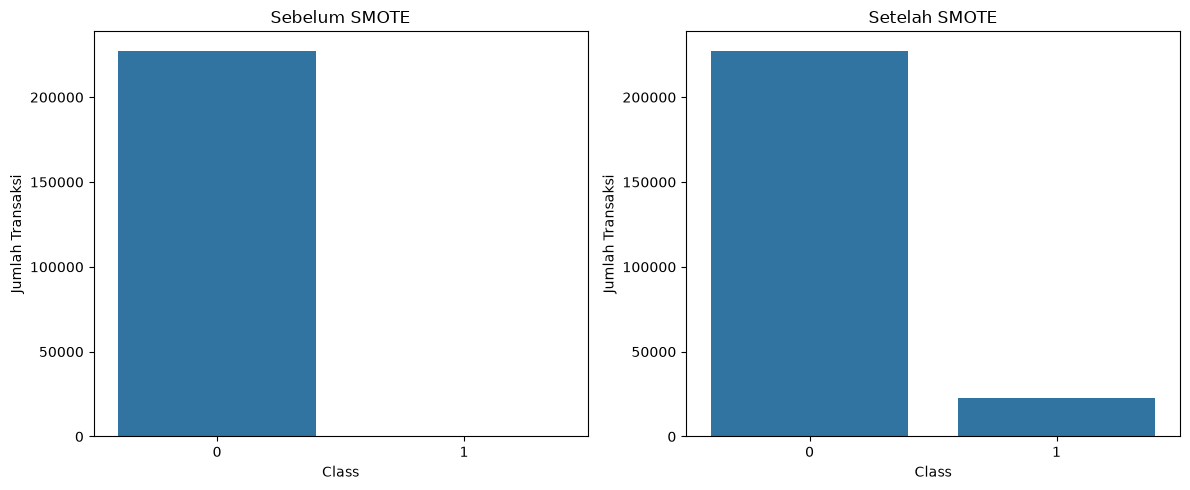

In [37]:

# bandingkan distribusi kelas sebelum dan sesudah SMOTE

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title('Sebelum SMOTE')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Jumlah Transaksi')

sns.countplot(x=y_train_smote, ax=axes[1])
axes[1].set_title('Setelah SMOTE')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Jumlah Transaksi')

plt.tight_layout()
plt.show()



SMOTE diterapkan dengan `sampling_strategy=0.1`, sehingga jumlah kelas minoritas ditingkatkan hingga sekitar 10% dari jumlah kelas mayoritas pada data latih. Pengaturan ini digunakan sebagai pendekatan oversampling parsial agar ketimpangan kelas berkurang tanpa harus membuat kedua kelas memiliki jumlah sampel yang sama.

Data uji tidak mengalami resampling karena digunakan untuk mengukur performa model pada distribusi kelas yang asli.



## 4. Membangun Model Klasifikasi

Model yang digunakan adalah Random Forest, yaitu metode ensemble yang menggabungkan prediksi dari sejumlah decision tree. Dua model dibandingkan dengan parameter yang sama:

1. Random Forest tanpa penanganan class imbalance.
2. Random Forest dengan data latih yang telah ditangani menggunakan SMOTE.

Perbandingan ini digunakan untuk mengamati pengaruh SMOTE terhadap kemampuan model dalam mengenali transaksi fraud.


In [38]:

# model pertama: Random Forest tanpa SMOTE
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

print('Model Random Forest tanpa SMOTE selesai dilatih.')


Model Random Forest tanpa SMOTE selesai dilatih.


In [40]:

# model kedua: Random Forest dengan SMOTE
model_rf_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_rf_smote.fit(X_train_smote, y_train_smote)

print('Model Random Forest dengan SMOTE selesai dilatih.')


Model Random Forest dengan SMOTE selesai dilatih.



## 5. Evaluasi Model

Evaluasi dilakukan menggunakan data uji yang sama untuk kedua model. Metrik yang digunakan adalah precision, recall, F1-score, dan AUC-ROC. Accuracy juga dihitung sebagai metrik tambahan, tetapi tidak dijadikan satu-satunya dasar penilaian karena distribusi kelas dataset tidak seimbang.

Evaluasi difokuskan pada kelas fraud (Class = 1), karena transaksi fraud merupakan kelas minoritas yang perlu dikenali dengan baik.


In [41]:

# fungsi evaluasi model
def evaluasi_model(nama_model, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    hasil = {
        'Model': nama_model,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ),
        'F1-score': f1_score(
            y_test, y_pred, zero_division=0
        ),
        'AUC-ROC': roc_auc_score(y_test, y_prob)
    }

    print(f'=== {nama_model} ===')
    print(classification_report(
        y_test,
        y_pred,
        target_names=['Normal (0)', 'Fraud (1)'],
        zero_division=0
    ))

    return hasil


In [42]:

# evaluasi kedua model
hasil_rf = evaluasi_model(
    'Random Forest tanpa SMOTE',
    model_rf,
    X_test,
    y_test
)

hasil_rf_smote = evaluasi_model(
    'Random Forest dengan SMOTE',
    model_rf_smote,
    X_test,
    y_test
)


=== Random Forest tanpa SMOTE ===
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00     56864
   Fraud (1)       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962

=== Random Forest dengan SMOTE ===
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00     56864
   Fraud (1)       0.86      0.87      0.86        98

    accuracy                           1.00     56962
   macro avg       0.93      0.93      0.93     56962
weighted avg       1.00      1.00      1.00     56962



In [43]:

# tabel perbandingan performa
hasil_perbandingan = pd.DataFrame([
    hasil_rf,
    hasil_rf_smote
])

hasil_perbandingan = hasil_perbandingan.set_index('Model')

display(hasil_perbandingan.round(4))


,Accuracy,Precision,Recall,F1-score,AUC-ROC
Model,,,,,
Random Forest tanpa SMOTE,0.9996,0.9412,0.8163,0.8743,0.9630
Random Forest dengan SMOTE,0.9995,0.8586,0.8673,0.8629,0.9643



### 5.1 Confusion Matrix

Confusion matrix digunakan untuk melihat jumlah prediksi benar dan salah pada setiap kelas. Pada kasus ini, perhatian khusus diberikan pada transaksi fraud yang berhasil dikenali dan transaksi fraud yang salah diprediksi sebagai normal.


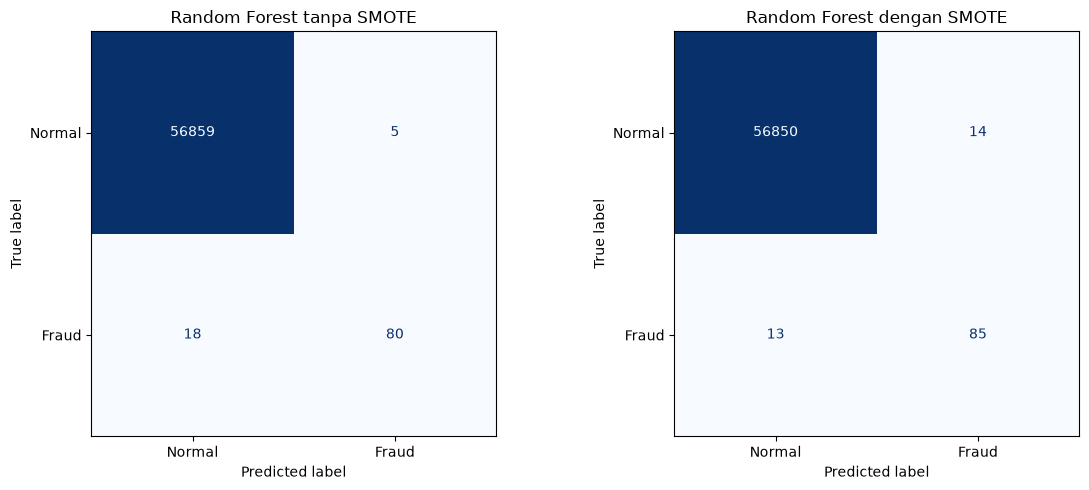

In [45]:

# bandingkan confusion matrix kedua model
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    model_rf,
    X_test,
    y_test,
    display_labels=['Normal', 'Fraud'],
    cmap='Blues',
    ax=axes[0],
    colorbar=False
)

axes[0].set_title('Random Forest tanpa SMOTE')

ConfusionMatrixDisplay.from_estimator(
    model_rf_smote,
    X_test,
    y_test,
    display_labels=['Normal', 'Fraud'],
    cmap='Blues',
    ax=axes[1],
    colorbar=False
)

axes[1].set_title('Random Forest dengan SMOTE')

plt.tight_layout()
plt.show()



Pada confusion matrix, *true positive* (TP) menunjukkan transaksi fraud yang berhasil diprediksi sebagai fraud, sedangkan *false negative* (FN) menunjukkan transaksi fraud yang diprediksi sebagai transaksi normal.

Model dengan jumlah FN lebih sedikit berarti lebih banyak transaksi fraud yang berhasil terdeteksi. Namun, hasil tersebut tetap perlu dibandingkan dengan jumlah *false positive* (FP), yaitu transaksi normal yang salah diprediksi sebagai fraud.


### 5.2 ROC curve

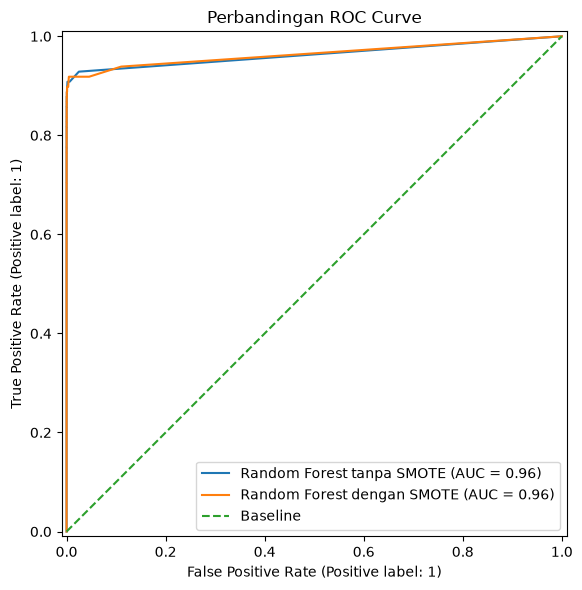

In [46]:

# perbandingan ROC curve
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(
    model_rf,
    X_test,
    y_test,
    name='Random Forest tanpa SMOTE',
    ax=ax
)

RocCurveDisplay.from_estimator(
    model_rf_smote,
    X_test,
    y_test,
    name='Random Forest dengan SMOTE',
    ax=ax
)

ax.plot([0, 1], [0, 1], linestyle='--', label='Baseline')
ax.set_title('Perbandingan ROC Curve')
ax.legend()

plt.tight_layout()
plt.show()


### 5.3 Perbandingan metrik

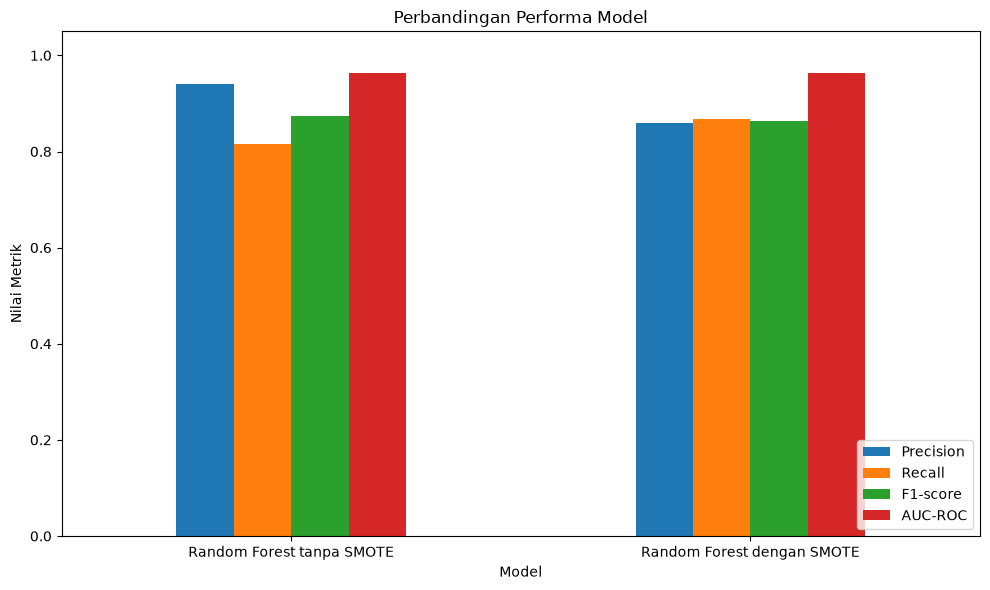

In [47]:

# visualisasi perbandingan metrik evaluasi
metrik = ['Precision', 'Recall', 'F1-score', 'AUC-ROC']

hasil_perbandingan[metrik].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Perbandingan Performa Model')
plt.xlabel('Model')
plt.ylabel('Nilai Metrik')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [48]:

# simpan tabel perbandingan hasil evaluasi
hasil_perbandingan.to_csv(
    '5054251013_Evina_Fitriyani_Hasil_Ensemble.csv'
)

print('Tabel hasil evaluasi berhasil disimpan.')


Tabel hasil evaluasi berhasil disimpan.



## 6. Analisis Hasil Evaluasi

Berdasarkan hasil evaluasi, model Random Forest tanpa SMOTE memperoleh accuracy 0,9996, precision 0,9412, recall 0,8163, F1-score 0,8743, dan AUC-ROC 0,9630. Sementara itu, model Random Forest dengan SMOTE memperoleh accuracy 0,9995, precision 0,8586, recall 0,8673, F1-score 0,8629, dan AUC-ROC 0,9643.

Penerapan SMOTE meningkatkan recall dari 0,8163 menjadi 0,8673 dan AUC-ROC dari 0,9630 menjadi 0,9643. Hal ini menunjukkan bahwa model dengan SMOTE mampu mengenali lebih banyak transaksi fraud. Namun, precision dan F1-score mengalami penurunan dibandingkan model tanpa SMOTE.

Accuracy saja tidak cukup untuk menilai performa model karena distribusi kelas sangat tidak seimbang, yaitu 99,8273% transaksi normal dan hanya 0,1727% transaksi fraud. Oleh karena itu, pemilihan model perlu mempertimbangkan precision, recall, F1-score, dan AUC-ROC. Model tanpa SMOTE memiliki F1-score dan precision lebih tinggi, sedangkan model dengan SMOTE memiliki recall dan AUC-ROC lebih tinggi.



## 7. Ringkasan

Praktikum ini menggunakan dataset Credit Card Fraud Detection yang terdiri dari 284.807 baris dan 31 kolom, dengan 284.315 transaksi normal dan 492 transaksi fraud. Dataset dibagi menjadi 80% data latih dan 20% data uji menggunakan stratifikasi, kemudian SMOTE diterapkan hanya pada data latih untuk mengatasi ketidakseimbangan kelas.

Dua model Random Forest, yaitu tanpa SMOTE dan dengan SMOTE, dibandingkan menggunakan precision, recall, F1-score, AUC-ROC, dan confusion matrix. Hasil evaluasi menunjukkan bahwa SMOTE meningkatkan recall dan AUC-ROC, tetapi menurunkan precision dan F1-score. Dengan demikian, kedua model memiliki kelebihan masing-masing dan pemilihannya bergantung pada prioritas deteksi fraud.